# Session 3 · From raw data to a trained model
**Dataset:** Auto MPG, 398 cars from 1970–1982. **Target:** fuel efficiency `mpg` (miles per gallon, higher = more efficient).

Part A: we work as a **data analyst** (what happened?). Part B: as a **data scientist** (what will happen?).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 2)

## Part A · Data analyst
### 1 · Load and first look

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
df.info()          # columns, types, non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 35.9 KB


In [4]:
df.describe()      # count, mean, min, max, quartiles

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.00,398.00,398.00,392.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.47,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.49,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.83,73.00
50%,23.00,4.00,148.50,93.50,2803.50,15.50,76.00
75%,29.00,8.00,262.00,126.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


### 2 · Data quality
Four questions for every dataset: **missing values, duplicates, outliers, wrong types.**

In [5]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [6]:
df[df["horsepower"].isnull()]     # which cars are affected?

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0,4,98.0,NaN,2046,19.0,71,usa,ford pinto
126,21.0,6,200.0,NaN,2875,17.0,74,usa,ford maverick
330,40.9,4,85.0,NaN,1835,17.3,80,europe,renault lecar deluxe
336,23.6,4,140.0,NaN,2905,14.3,80,usa,ford mustang cobra
354,34.5,4,100.0,NaN,2320,15.8,81,europe,renault 18i
374,23.0,4,151.0,NaN,3035,20.5,82,usa,amc concord dl


In [7]:
df.duplicated().sum()

np.int64(0)

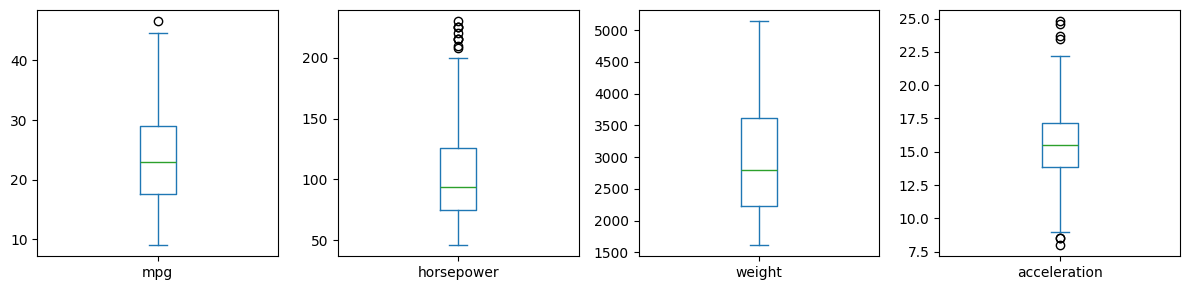

In [8]:
cols = ["mpg", "horsepower", "weight", "acceleration"]
df[cols].plot(kind="box", subplots=True, layout=(1, 4), figsize=(12, 3))
plt.tight_layout()

In [9]:
# IQR rule: a value is an outlier if it is more than 1.5 × IQR outside the middle 50 %
q1, q3 = df["horsepower"].quantile([0.25, 0.75])
iqr = q3 - q1
df[df["horsepower"] > q3 + 1.5 * iqr][["name", "horsepower"]]

,name,horsepower
6,chevrolet impala,220.0
7,plymouth fury iii,215.0
8,pontiac catalina,225.0
13,buick estate wagon (sw),225.0
25,ford f250,215.0
27,dodge d200,210.0
67,mercury marquis,208.0
94,chrysler new yorker brougham,215.0
95,buick electra 225 custom,225.0
116,pontiac grand prix,230.0


**Decisions:** 6 missing `horsepower` → we fill them, but *later*, inside the pipeline, after the split (otherwise: leakage). No duplicates. The high-horsepower cars are real cars, not typos → keep them. Types look right.

### 3 · Explore: answer questions with data

In [10]:
# Q1: Which region builds the most efficient cars?
df.groupby("origin")["mpg"].agg(["mean", "count"])

,mean,count
origin,,
europe,27.89,70
japan,30.45,79
usa,20.08,249


In [11]:
# Q2: Do more cylinders mean lower mpg?
df.groupby("cylinders")["mpg"].mean()

cylinders
3    20.55
4    29.29
5    27.37
6    19.99
8    14.96
Name: mpg, dtype: float64

Text(0.5, 1.0, 'Heavier cars use more fuel')

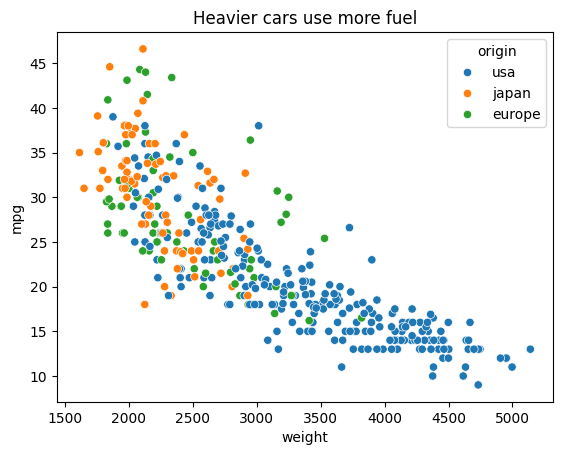

In [12]:
# Q3: How does weight relate to mpg?
sns.scatterplot(data=df, x="weight", y="mpg", hue="origin")
plt.title("Heavier cars use more fuel")

Text(0, 0.5, 'mean mpg')

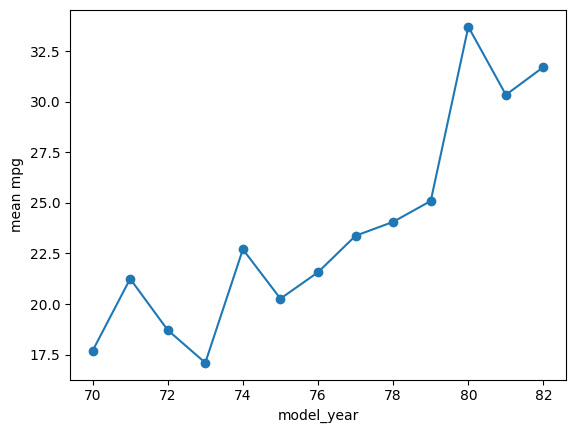

In [13]:
# Q4: Did cars get more efficient over the years?
df.groupby("model_year")["mpg"].mean().plot(marker="o")
plt.ylabel("mean mpg")

<Axes: >

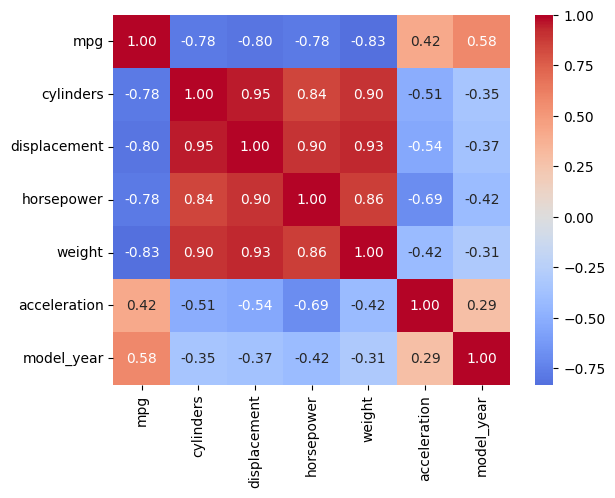

In [14]:
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)

Careful: correlation is not causation. `model_year` correlates with `mpg`, but the year doesn't make the car efficient: the oil crises of 1973 and 1979 changed what was built.

## Part B · Data scientist
### 4 · Feature engineering

In [15]:
df["power_to_weight"] = df["horsepower"] / df["weight"]   # create
df = df.drop(columns=["name"])                               # drop: 305 unique names, no pattern

X = df.drop(columns=["mpg"])
y = df["mpg"]
X.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,power_to_weight
0,8,307.0,130.0,3504,12.0,70,usa,0.04
1,8,350.0,165.0,3693,11.5,70,usa,0.04
2,8,318.0,150.0,3436,11.0,70,usa,0.04
3,8,304.0,150.0,3433,12.0,70,usa,0.04
4,8,302.0,140.0,3449,10.5,70,usa,0.04


### 5 · Split first, then touch the data

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train /", len(X_test), "test")

318 train / 80 test


In [17]:
# Why split first? Any statistic computed on ALL data leaks the test set into training.
print("median horsepower, all data :", X["horsepower"].median())
print("median horsepower, train only:", X_train["horsepower"].median())

median horsepower, all data : 93.5
median horsepower, train only: 92.0


### 6 · Scaling and pipelines
Why scale? Gradient descent: a feature like `weight` (≈ 3000) gets a huge slope, `acceleration` (≈ 15) a tiny one. One learning rate can't fit both.

In [18]:
from sklearn.linear_model import SGDRegressor

num = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "power_to_weight"]
Xn = X_train[num].fillna(X_train[num].median())

sgd = SGDRegressor(max_iter=1000, random_state=0).fit(Xn, y_train)
print("unscaled, first weights:", sgd.coef_[:3])     # explodes

unscaled, first weights: [-9.04759259e+10  9.28046111e+11 -3.04515303e+12]


In [19]:
from sklearn.preprocessing import StandardScaler

Xs = StandardScaler().fit_transform(Xn)
sgd = SGDRegressor(max_iter=1000, random_state=0).fit(Xs, y_train)
print("scaled, first weights:", sgd.coef_[:3].round(2))

scaled, first weights: [ 0.09 -0.26  0.84]


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # fit on train only, automatically
    ("scale", StandardScaler()),
])
preprocess = ColumnTransformer([
    ("num", numeric, num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["origin"]),
])

### 7 · Finally: train

In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

def evaluate(name, model, cols=num):
    pre = ColumnTransformer([("num", numeric, cols),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), ["origin"])])
    pipe = Pipeline([("prep", pre), ("model", model)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    return {"model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": root_mean_squared_error(y_test, pred)}, pipe

raw = [c for c in num if c != "power_to_weight"]
results = []
for name, model, cols in [
    ("Baseline: always the mean", DummyRegressor(strategy="mean"), num),
    ("Linear regression", LinearRegression(), raw),
    ("Linear + power_to_weight", LinearRegression(), num),
    ("Random forest", RandomForestRegressor(n_estimators=300, random_state=42), num),
]:
    r, pipe = evaluate(name, model, cols)
    results.append(r)
pd.DataFrame(results)

,model,MAE,RMSE
0,Baseline: always the mean,5.96,7.35
1,Linear regression,2.29,2.89
2,Linear + power_to_weight,2.22,2.78
3,Random forest,1.63,2.18


Text(0.5, 1.0, 'What the random forest relies on')

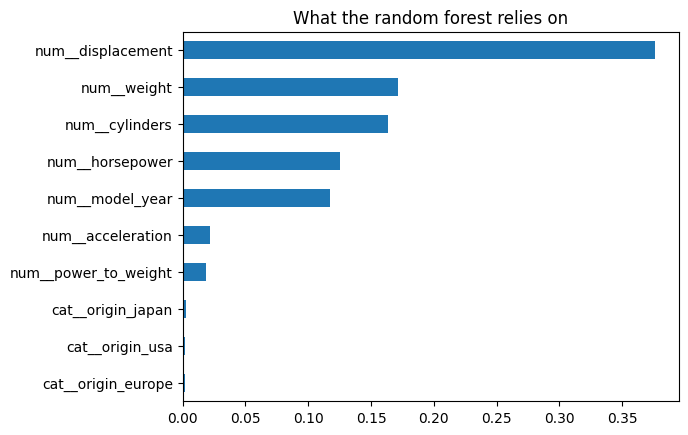

In [22]:
rf = pipe.named_steps["model"]
names = pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=names).sort_values()
imp.plot(kind="barh")
plt.title("What the random forest relies on")

**Next session (chapter 04 Testing):** Is one test split enough? Cross-validation, overfitting, and what MAE = 2 mpg actually means.